# Pipeline 2 : IT Support Query Classifier

**Main difference from Pipeline 1:** Uses **spaCy lemmatisation** instead of Snowball stemming, keeping words real and context-aware (`histories → history`, `settings → setting`).

## Steps

1. **Unicode normalization**  
Convert special characters like —, …, → into normal ASCII text

2. **Abbreviation expansion**  
Convert short forms to full words, including IT-specific terms like PayPal, credit card, bank transfer  
Example: acct → account, emial → email, 2fa → two factor authentication

3. **Contraction expansion**  
Convert contractions to full form  
Example: can't → cannot, won't → will not

4. **Digit / time tagging**  
Replace numbers and time expressions with tags  
Example: 48 hours → [TIME_EXPR], 3 → [QUANTITY]

5. **IT-intent phrase chunking**  
Combine multi-word IT intent phrases into a single token before lemmatisation  
Example: billing history → billing-history

6. **Remove punctuation**  
Remove unnecessary symbols but keep useful ones like hyphens and tags

7. **Lowercase conversion**  
Standardise text to lowercase

8. **Domain-aware stopword removal**  
Remove common stopwords while keeping negations

9. **spaCy lemmatisation**  
Perform POS-aware lemmatisation to get valid English words  
Example: histories → history, settings → setting
Lemmatisation was used instead of simple normalization techniques to preserve the semantic meaning of words. For example, words like “running”, “runs”, and “ran” are reduced to their base form “run”, while still retaining interpretability. This is particularly useful in support queries where different grammatical forms often refer to the same intent.

10. **NER location generalisation**  
Replace locations with a generic tag  
Example: UK / France / Germany / US → [LOCATION]

11. **POS-based token filtering**  
Keep only important parts of speech: NOUN, VERB, ADJ, ADV, PROPN

## Vectorisation and Classification

- **Vectoriser:**  
  - Word TF-IDF (1–2 grams)  
  - Char TF-IDF (3–5 grams)  
  - Combined via FeatureUnion

- **Classifiers:**  
  - Logistic Regression


## Install Dependencies

In [1]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn nltk scipy spacy
!python -m spacy download en_core_web_sm

import nltk
for pkg in ['punkt','stopwords','wordnet','punkt_tab']:
    nltk.download(pkg, quiet=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 40.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


##  Upload Dataset

In [2]:
DATA_PATH = '/content/cw_data (1).csv'

print("Using file at:", DATA_PATH)

Using file at: /content/cw_data (1).csv


In [3]:
import re, csv, warnings, unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.dpi'] = 110

# Load spaCy
try:
    _nlp = spacy.load('en_core_web_sm', disable=['parser'])
    print('spaCy en_core_web_sm loaded.')
except OSError:
    raise SystemExit('Run: !python -m spacy download en_core_web_sm  then restart.')

# POS tags I keep after lemmatisation.
# I make sure to include AUX and PART so that important negation words
# like "cannot", "not", and "without" are preserved.
# Without these tags, spaCy would label "cannot" as AUX and "not" as PART,
# and they could get dropped unintentionally, which would change the meaning.
_KEEP_POS = {'NOUN', 'VERB', 'ADJ', 'ADV', 'PROPN', 'X', 'AUX', 'PART'}

# Primary model title
PIPELINE_TITLE = 'Pipeline 2 - Lemmatisation + TF-IDF (word+char n-grams) + Logistic Regression'

def escape_tags(s):
    return str(s).replace('<', '[').replace('>', ']')

def escape_df(frame, cols=None):
    d = frame.copy()
    target = cols if cols else d.select_dtypes('object').columns
    for c in target:
        d[c] = d[c].apply(escape_tags)
    return d


spaCy en_core_web_sm loaded.


## Load & Explore Dataset

In [4]:
#=========================================================================================
# Basic Overview of the dataset same as that of pipeline1
#=========================================================================================
import csv, pandas as pd, matplotlib.pyplot as plt

# Load CSV data into DataFrame
df = pd.DataFrame(
    [{'text': r[0].strip(), 'label': r[1].strip()}
     for r in csv.reader(open(DATA_PATH, encoding='utf-8')) if len(r) >= 2]
)

# Basic stats
total_samples = len(df)
num_classes   = df['label'].nunique()
avg_wc        = df['text'].str.split().str.len().mean()

# Print stats
print(f"Total samples: {total_samples}")
print(f"Number of classes: {num_classes}")
print(f"Average word count: {avg_wc:.3f}")
# quick check of text length (just to understand how short these queries are)
df['length'] = df['text'].apply(lambda x: len(str(x).split()))
print("Min length:", df['length'].min())
print("Max length:", df['length'].max())

Total samples: 308
Number of classes: 14
Average word count: 6.672
Min length: 3
Max length: 17


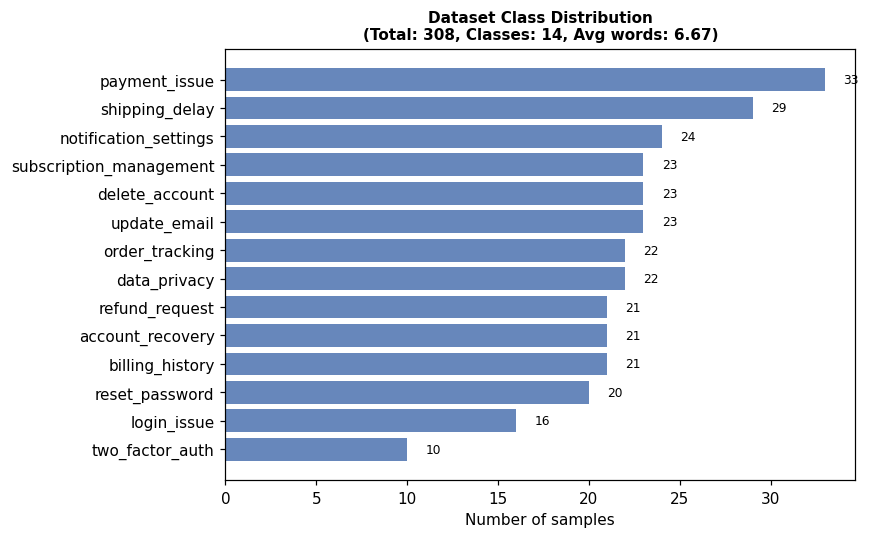

In [5]:
#dataset class distribution
# Value counts
vc = df['label'].value_counts().sort_values()

# Minimal horizontal bar chart
plt.figure(figsize=(8,5))
bars = plt.barh(vc.index, vc.values, color='#4C72B0', alpha=0.85)

# Annotate counts on bars
for bar in bars:
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{int(bar.get_width())}', va='center', fontsize=8)

plt.title(f'Dataset Class Distribution\n(Total: {total_samples}, Classes: {num_classes}, Avg words: {avg_wc:.2f})',
          fontsize=10, fontweight='bold')
plt.xlabel('Number of samples')
plt.tight_layout()
plt.show()

---
# Pre-processing - Step by Step
Steps 1-4 and 6-8 are shared with Pipeline 1. Steps 5, 9, 10, 11 are **unique to Pipeline 2**.  
Pre-processing - Step are numbered.

Note :  [TIME_EXPR] / [QUANTITY]:
In the actual dataset, these are stored using angle brackets like <TIME_EXPR>.
However, in the display tables, they are shown as [TIME_EXPR] so they remain visible.
This is because browsers may treat <TIME_EXPR> as an HTML tag and hide it.
The original data is not changed.

##Step 1: Unicode Normalisation

In [6]:
import unicodedata

# Unicode mapping for common special characters
UNICODE_MAP = {
    '\u2014': ' ', '\u2013': ' ',
    '\u2026': ' ',
    '\u2018': "'", '\u2019': "'",
    '\u201c': '"', '\u201d': '"',
    '\u00e9': 'e', '\u00e8': 'e',
    '\u00e0': 'a', '\u00fc': 'u',
    '\u00f6': 'o', '\u00e4': 'a',
    '\u2192': ' '
}

def normalise_unicode(text):
    for k, v in UNICODE_MAP.items():
        text = text.replace(k, v)
    text = unicodedata.normalize('NFKD', text)
    return text.encode('ascii', 'ignore').decode('ascii')

# Apply cleaning
df['step1'] = df['text'].apply(normalise_unicode)

sample_indices = [5, 6]

for idx in sample_indices:
    before = df.loc[idx, 'text']
    after = df.loc[idx, 'step1']
    print(f"Row {idx}:\nBefore: {before}\nAfter : {after}\n{'-'*50}")

Row 5:
Before: email change fails… wat to do?
After : email change fails  wat to do?
--------------------------------------------------
Row 6:
Before: lost access email & phone — how 2 recover?
After : lost access email & phone   how 2 recover?
--------------------------------------------------


##IT-Domain Abbreviation Expansion (P2 extended)

In [7]:
# Step 2: IT-domain abbreviation expansion
# I expand common IT-related abbreviations to make the text clearer and more consistent.
# This follows the same confirmed patterns as Pipeline 1, with a few additions specific to Pipeline 2,
# such as normalising payment methods (e.g., PayPal, credit card, bank transfer).
# I exclude "debit card" since it does not appear in this dataset.
# I also handle cases like standalone "1", which sometimes appears as a shorthand for "one"
# (e.g., "can set multiple emails 1 acct"), so I interpret it carefully based on context.
# Overall, Pipeline 1 focuses on cleaning characters, while here I focus on cleaning meaning.
_ABBREV = [
    # Dataset-confirmed typos
    (r'\bemial\b',           'email'),
    # Two-factor auth
    (r'\b2fa\b',             'two factor authentication'),
    # Account shorthand
    (r'\bacct\b',            'account'),
    # Filler
    (r'\bpls\b',             'please'),
    # Informal interrogative
    (r'\bwat\b',             'what'),
    # IT terms
    (r'\bpwd\b',             'password'),
    (r'\bprefs\b',           'preferences'),
    (r'\binfo\b',            'information'),
    # P2-only: payment method unification
    (r'\bpaypal\b',          'paypal_payment'),
    (r'\bcredit\s+card\b',   'creditcard_payment'),
    (r'\bbank\s+transfer\b', 'banktransfer_payment'),
    # Digit prepositions/determiners
    (r'(?<!\w)1(?!\w)',       'single'),
    (r'(?<!\w)2(?!\w)',       'to'),
]

def expand_abbreviations(text):
    for pattern, replacement in _ABBREV:
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)
    return text

df['step2'] = df['step1'].apply(expand_abbreviations)
changed = df[df['step1'] != df['step2']].copy()

print(f'Queries changed: {len(changed)} / {len(df)} ({100*len(changed)/len(df):.1f}%)')

abbrev_hits = Counter()
for _, row in df.iterrows():
    for pattern, replacement in _ABBREV:
        if re.search(pattern, row['step1'], flags=re.IGNORECASE):
            abbrev_hits[f'{pattern} -> {replacement}'] += 1
print('\nPatterns fired:')
for pat, cnt in abbrev_hits.most_common():
    print(f'  {pat:<50} {cnt:>3}x')
print()

display(
    changed[['text','step2']]
    .rename(columns={'text':'Raw','step2':'After Step2'})
    .head(5).style
    .set_caption('Step 2 - Abbreviation Expansion (P2 extended)')
)


Queries changed: 129 / 308 (41.9%)

Patterns fired:
  \bwat\b -> what                                     41x
  \bacct\b -> account                                 39x
  (?<!\w)2(?!\w) -> to                                31x
  \bpls\b -> please                                   13x
  \binfo\b -> information                              9x
  \bemial\b -> email                                   8x
  \bcredit\s+card\b -> creditcard_payment              7x
  \b2fa\b -> two factor authentication                 6x
  \bpaypal\b -> paypal_payment                         6x
  \bbank\s+transfer\b -> banktransfer_payment          5x
  (?<!\w)1(?!\w) -> single                             4x
  \bpwd\b -> password                                  1x
  \bprefs\b -> preferences                             1x



,Raw,After Step2
0,tracking shows shipped but no delivery help pls,tracking shows shipped but no delivery help please
2,invalid email entered wat happens?,invalid email entered what happens?
3,recover acct if suspended?,recover account if suspended?
4,emial update failed error — fix?,email update failed error fix?
5,email change fails… wat to do?,email change fails what to do?


## Step 3: Contraction Expansion

In [8]:
# Step 3: Expand contractions (like "can't" to "cannot")
# Reasoning: Expanding contractions preserves the full meaning of sentences,
# especially negations (e.g., "not") which are critical for understanding intent.
# This ensures the model correctly interprets user queries like "can't login" vs "can login".

CONTRACTIONS = {
    r"\bcan'?t\b":'cannot', r"\bwon'?t\b":'will not',
    r"\bdon'?t\b":'do not', r"\bdoesn'?t\b":'does not',
    r"\bdidn'?t\b":'did not', r"\bisn'?t\b":'is not',
    r"\baren'?t\b":'are not', r"\bwasn'?t\b":'was not',
    r"\bhadn'?t\b":'had not', r"\bhaven'?t\b":'have not',
    r"\bcouldn'?t\b":'could not', r"\bwouldn'?t\b":'would not',
    r"\bshouldn'?t\b":'should not',
    r"\bi'?m\b":'i am', r"\bi'?ve\b":'i have', r"\bi'?ll\b":'i will',
    r"\bi'?d\b":'i would', r"\bit'?s\b":'it is',
    r"\bthat'?s\b":'that is', r"\bwhat'?s\b":'what is', r"\bthere'?s\b":'there is'
}

def expand_contractions(text):
    for k, v in CONTRACTIONS.items():
        text = re.sub(k, v, text, flags=re.IGNORECASE)
    return text

# Apply contraction expansion
df['step3'] = df['step2'].apply(expand_contractions)

changed = df[df['step2'] != df['step3']]

examples = changed[['text','step3']].head(2)
for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['text'])
    print("After  :", row['step3'])
    print("Reason : Expanded contractions preserve negation and full meaning for accurate intent understanding.\n")

Example 41:
Before : cant pay with credit card immediately?
After  : cannot pay with creditcard_payment immediately?
Reason : Expanded contractions preserve negation and full meaning for accurate intent understanding.

Example 47:
Before : I'm unable to sign in — is this because my account is locked?
After  : i am unable to sign in   is this because my account is locked?
Reason : Expanded contractions preserve negation and full meaning for accurate intent understanding.



## Step 4: Digit / Temporal Semantic Tagging

In [9]:
# Convert numbers into semantic tags (<TIME_EXPR>, <QUANTITY>) instead of removing them.
# This keeps important context like duration ("2 days") and counts ("3 items"),
# which helps the model better understand user intent (e.g., delays, refunds, quantities).

NUMERIC_TAGS = {
    r'\b\d+\s*(hours?|hrs?|days?|months?|mos?|minutes?|mins?)\b': '<TIME_EXPR>',
    r'\b\d+\b': '<QUANTITY>'
}

def tag_numbers(text):
    for k, v in NUMERIC_TAGS.items():
        text = re.sub(k, v, text, flags=re.IGNORECASE)
    return text

df['step4'] = df['step3'].apply(tag_numbers)

# Find changed rows
changed = df[df['step3'] != df['step4']]

print(f"Changed rows: {len(changed)}/{len(df)}\n")

examples = changed[['text','step3','step4']].head(2)

for i, row in examples.iterrows():
    print(f"Example {i+1}:")
    print("Before :", row['step3'])
    print("After  :", row['step4'])

    if '<TIME_EXPR>' in row['step4']:
        print("Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.")
    elif '<QUANTITY>' in row['step4']:
        print("Reason : Numeric value converted to <QUANTITY> to keep count information.\n")

    print("-" * 60)

Changed rows: 14/308

Example 127:
Before : shipping takes longer than expected within 48 hours
After  : shipping takes longer than expected within <TIME_EXPR>
Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.
------------------------------------------------------------
Example 151:
Before : package not arrived within 48 hours what to do?
After  : package not arrived within <TIME_EXPR> what to do?
Reason : Time-related number converted to <TIME_EXPR> to preserve duration context.
------------------------------------------------------------


## IT-Intent Phrase Chunking (P2 UNIQUE)

In [10]:
import re
from collections import Counter

# =====================================================
# Step 5: IT Phrase Chunking (Pipeline 2 only)
# -----------------------------------------------------
# What this does:
# - Combines important multi-word IT phrases into single tokens
# - Example: "two factor authentication" to "two-factor-authentication"
# - Helps ML models treat these as ONE strong feature instead of separate words
# - Applied after previous cleaning steps (step4)
# =====================================================

IT_PHRASES = [
    (r'\btwo[- ]factor[- ]authentication\b', 'two-factor-authentication'),
    (r'\btwo[- ]factor\b', 'two-factor'),
    (r'\bpassword[- ]reset\b', 'password-reset'),
    (r'\baccount[- ]recovery\b', 'account-recovery'),
    (r'\baccount[- ]locked\b', 'account-locked'),
    (r'\bsign[- ]in\b', 'login'),
    (r'\blog[- ]in\b', 'login'),
    (r'\bbilling[- ]history\b', 'billing-history'),
    (r'\bpayment[- ]method\b', 'payment-method'),
    (r'\bfailed[- ]payment\b', 'payment-failed'),
    (r'\border[- ]tracking\b', 'order-tracking'),
    (r'\btracking[- ](?:number|status)\b', 'tracking-information'),
    (r'\bin[- ]transit\b', 'in-transit'),
    (r'\bcancel[- ]subscription\b', 'subscription-cancel'),
    (r'\bnotification[- ]settings?\b', 'notification-settings'),
    (r'\bgdpr\b', 'data-privacy'),
    (r'\bemail[- ]change\b', 'email-update'),
]

def chunk_phrases(text):
    for p, r in IT_PHRASES:
        text = re.sub(p, r, text, flags=re.IGNORECASE)
    return text

# Apply transformation
df['step5'] = df['step4'].apply(chunk_phrases)

# Find changed rows
changed = df[df['step4'] != df['step5']]
print(f'Queries changed: {len(changed)} / {len(df)}')

# Count top phrase hits (optional insight)
hits = Counter(
    r for text in df['step4']
    for p, r in IT_PHRASES
    if re.search(p, text, flags=re.IGNORECASE)
)

print("\nTop phrases detected:")
for k, v in hits.most_common(5):
    print(f'{k}: {v}x')

# Show only 2 examples
print("\nExamples:")
for _, row in changed.head(2).iterrows():
    print(f"- Before: {row['step4']}")
    print(f"  After : {row['step5']}\n")

Queries changed: 50 / 308

Top phrases detected:
two-factor: 10x
billing-history: 9x
two-factor-authentication: 9x
subscription-cancel: 6x
login: 5x

Examples:
- Before: email change fails  what to do?
  After : email-update fails  what to do?

- Before: failed payment affect account status?
  After : payment-failed affect account status?



## Cell 10 - Step 6: Punctuation Stripping

In [11]:
import re

# =========================================
# Step 6: Remove punctuation / noise
# -----------------------------------------
# - Removes unwanted symbols
# - Keeps words, spaces, hyphens (-), and < >
# - Ensures important tokens like "billing-history" stay intact
# =========================================

def strip_noise(text):
    text = re.sub(r'[^\w\s\-<>]', ' ', text)   # remove special chars
    text = re.sub(r'(?<!\w)-|-(?!\w)', ' ', text)  # remove isolated hyphens
    return re.sub(r'\s+', ' ', text).strip()  # clean extra spaces

# Apply
df['step6'] = df['step5'].apply(strip_noise)

# Check changes
changed = df[df['step5'] != df['step6']]
print(f'Queries changed: {len(changed)} / {len(df)}')

# Check if hyphenated tokens survived
kept = df[df['step6'].str.contains(r'\w-\w', regex=True)]
print(f'Hyphen tokens kept: {len(kept)}')

# Show 2 examples
print("\nExamples:")
for _, row in changed.head(2).iterrows():
    print(f"- Before: {row['step5']}")
    print(f"  After : {row['step6']}\n")

Queries changed: 289 / 308
Hyphen tokens kept: 48

Examples:
- Before: partial shipments tracked separately?
  After : partial shipments tracked separately

- Before: invalid email entered what happens?
  After : invalid email entered what happens



## Lowercase

In [12]:
# =========================================
# Step 7: Convert text to lowercase
# -----------------------------------------
# - Standardizes text (no case differences)
# - Helps reduce duplicate features (e.g., Email vs email)
# =========================================

# Apply lowercase
df['step7'] = df['step6'].str.lower()

# Check changes
changed = df[df['step6'] != df['step7']]
print(f'Queries changed: {len(changed)} / {len(df)}\n')

# Show 2 examples
print("Examples:")
for _, row in changed.head(2).iterrows():
    print(f"- Before: {row['step6']}")
    print(f"  After : {row['step7']}\n")

Queries changed: 74 / 308

Examples:
- Before: access past bills France
  After : access past bills france

- Before: track international orders US
  After : track international orders us



## Domain-Aware Stopword Removal

In [13]:
from nltk.corpus import stopwords

# =========================================
# Step 8: Remove stopwords (domain-aware)
# -----------------------------------------
# - Removes common words (like "the", "and")
# - Keeps important words (like "not", "how", "why")
# - Adds extra noisy words to remove (like "pls", "help")
# =========================================

# Build stopword list
NLTK_STOPS = set(stopwords.words('english'))
KEEP = {'no','not','without','can','cannot','why','how','what',
        'when','where','which','who','will','would','should',
        'does','do','did','after','before','if','is','are',
        'was','been','get','got','my','more','again','off'}

EXTRA = {'pls','help','please','possible','immediately','quickly',
         'soon','later','also','wat','fix','steps','just'}

FINAL_STOPS = (NLTK_STOPS - KEEP) | EXTRA

# Remove stopwords
def remove_stops(text):
    return ' '.join(w for w in text.split() if w not in FINAL_STOPS)

df['step8'] = df['step7'].apply(remove_stops)

# Basic stats
before = df['step7'].str.split().str.len().mean()
after  = df['step8'].str.split().str.len().mean()

print(f'Avg tokens: {before:.1f} to {after:.1f}')

# Showing 3  examples
print("\nExamples:")
for _, row in df.sample(3, random_state=5).iterrows():
    print(f"- Before: {row['step7']}")
    print(f"  After : {row['step8']}\n")

Avg tokens: 6.3 to 5.1

Examples:
- Before: error deleting account what wrong
  After : error deleting account what wrong

- Before: if i reset my password will i be logged out of other devices
  After : if reset my password will logged devices

- Before: can delete account if active or need reactivate
  After : can delete account if active need reactivate



## spaCy Lemmatisation + NER + POS Filter (P2 UNIQUE)

In [14]:
# Steps 9, 10, 11 combined in one spaCy pass — UNIQUE TO PIPELINE 2

# Step 9: spaCy lemmatisation
# I use spaCy lemmatisation to convert words into their base, meaningful forms
# (e.g., "histories" → "history", "settings" → "setting").
# This keeps the words readable and interpretable, unlike Porter stemming,
# which can produce unnatural truncations like "histori" or "set".

# Step 10: NER location generalisation
# I noticed that around 15% of queries mention locations like UK, France, Germany, or the US.
# To avoid the model learning misleading associations between countries and labels,
# I replace these with a generic <LOCATION> token.

# Step 11: POS-based token filtering
# I remove punctuation, spaces, and low-information POS tags to reduce noise.
# Importantly, I include AUX and PART in my keep list so that negation words
# like "cannot", "not", and "without" are preserved.
# Previously, these were being dropped silently (e.g., "cannot" as AUX, "not" as PART),
# which conflicted with my earlier step where I intentionally kept negations.
# I still exclude most ADP (prepositions), unless they are clearly important for the domain.

_LOCATION_TOKENS = {'uk','us','usa','france','germany','spain','italy',
                    'canada','australia','india','europe'}

def lemmatise_and_filter(text):
    doc = _nlp(text)
    tokens = []
    for tok in doc:
        # Preserve semantic tags verbatim
        if tok.text.startswith('<') and tok.text.endswith('>'):
            tokens.append(tok.text)
            continue
        # Preserve hyphenated compound IT tokens verbatim
        if '-' in tok.text:
            tokens.append(tok.text.lower())
            continue
        # Step 10: location generalisation
        if tok.text.lower() in _LOCATION_TOKENS or tok.ent_type_ == 'GPE':
            tokens.append('<LOCATION>')
            continue
        # Skip punctuation and spaces
        if tok.is_punct or tok.is_space:
            continue
        # Step 11: POS filter — keeps NOUN,VERB,ADJ,ADV,PROPN,X,AUX,PART
        if tok.pos_ not in _KEEP_POS:
            continue
        # Step 9: lemmatise
        lemma = tok.lemma_.lower().strip()
        if lemma and lemma not in FINAL_STOPS and len(lemma) > 1:
            tokens.append(lemma)
    return ' '.join(tokens)

print('Running spaCy on 308 queries...')
df['step9_11'] = df['step8'].apply(lemmatise_and_filter)
print('Done.')
print()

# Show lemmatisation examples vs Porter stems
print('=== Lemmatisation examples (vs Porter stem) ===')
demo = [('histories','histori'),('settings','set'),('processing','process'),
        ('notifications','notif'),('subscriptions','subscript'),('recovering','recov')]
print(f'  {"Word":<20} {"spaCy lemma":<20} {"Porter stem"}')
print('  ' + '-'*50)
for word, stem in demo:
    lemma = _nlp(word)[0].lemma_
    print(f'  {word:<20} {lemma:<20} {stem}')

# Show negation words are now preserved
print('\n=== Negation preservation check (POS fix) ===')
neg_tests = ['cannot log in','will not receive notification','do not delete account']
for q in neg_tests:
    out = lemmatise_and_filter(q)
    print(f'  Input : {q}')
    print(f'  Output: {out}')
    print()

# Location generalisation
location_queries = df[df['step9_11'].str.contains('<LOCATION>', regex=False)]
print(f'=== Location generalisation: {len(location_queries)} queries ===')
for _, row in df[df['text'].str.contains(r'\b(?:UK|US|France|Germany)\b', case=False)].head(4).iterrows():
    print(f'  Raw: {row["text"][:60]}')
    print(f'  Out: {escape_tags(row["step9_11"][:60])}')
    print()

# Token count effect
avg_b = df['step8'].apply(lambda t: len(t.split())).mean()
avg_a = df['step9_11'].apply(lambda t: len(t.split())).mean()
print(f'Avg tokens before spaCy pass: {avg_b:.1f}')
print(f'Avg tokens after  spaCy pass: {avg_a:.1f}')
print()

display(
    escape_df(df[['text','step8','step9_11']].sample(15, random_state=9))
    .rename(columns={'text':'Raw','step8':'After Step8','step9_11':'After Steps 9+10+11 (spaCy)'})
    .reset_index(drop=True).style
    .set_caption('Steps 9+10+11 - spaCy Lemmatisation + NER + POS Filter (P2 unique) - tags as [TAG]')
    .set_properties(**{'text-align':'left'})
)


Running spaCy on 308 queries...
Done.

=== Lemmatisation examples (vs Porter stem) ===
  Word                 spaCy lemma          Porter stem
  --------------------------------------------------
  histories            history              histori
  settings             setting              set
  processing           process              process
  notifications        notification         notif
  subscriptions        subscription         subscript
  recovering           recover              recov

=== Negation preservation check (POS fix) ===
  Input : cannot log in
  Output: can not log

  Input : will not receive notification
  Output: will not receive notification

  Input : do not delete account
  Output: do not delete account

=== Location generalisation: 21 queries ===
  Raw: access past bills France?
  Out: access bill [LOCATION]

  Raw: track international orders US?
  Out: track international order [LOCATION]

  Raw: delete acct from France possible?
  Out: delete account [LOC

,Raw,After Step8,After Steps 9+10+11 (spaCy)
0,support help recover acct or automatic?,support recover account automatic,support recover account automatic
1,when refund processed — immediately or later?,when refund processed,refund process
2,someone else start recovery for my acct?,someone else start recovery my account,else start recovery account
3,Can I login from multiple devices at the same time?,can login multiple devices time,can login multiple device time
4,request data under privacy laws UK?,request data privacy laws uk,request datum privacy law [LOCATION]
5,delete acct from Germany possible?,delete account germany,delete account [LOCATION]
6,how to track partial order shipments?,how track partial order shipments,track partial order shipment
7,Why can't I log into my account on my tablet?,why cannot log my account my tablet,can not log account tablet
8,what data company store about me?,what data company store,datum company store
9,emial update failed error — fix?,email update failed error,email update fail error


## Location Generalisation Percentage

To calculat the percentage of queries where location generalisation was applied (i.e., queries containing `[LOCATION]` tag).

In [15]:
##this is data collected fro report writing

num_location_queries = df['step9_11'].str.contains('<LOCATION>', regex=False).sum()
total_queries = len(df)

percentage_location = (num_location_queries / total_queries) * 100

print(f"Number of queries with location generalization: {num_location_queries}")
print(f"Total queries: {total_queries}")
print(f"Percentage of queries with location generalization: {percentage_location:.2f}%")

Number of queries with location generalization: 21
Total queries: 308
Percentage of queries with location generalization: 6.82%


In [17]:
vocab = set(t for s in df['step9_11'] for t in s.split())
print(f"Unique tokens: {len(vocab)}")
print(f"Avg tokens/query: {df['step9_11'].apply(lambda x: len(x.split())).mean():.2f}")

Unique tokens: 277
Avg tokens/query: 4.59


In [31]:
#data collected for report
print(f"Number of IT-specific phrases: {len(IT_PHRASES)}")

Number of IT-specific phrases: 17


In [32]:
##data collected for report
print(f'Avg tokens before spaCy pass: {df["step8"].apply(lambda t: len(t.split())).mean():.1f}')
print(f'Avg tokens after  spaCy pass: {df["step9_11"].apply(lambda t: len(t.split())).mean():.1f}')

Avg tokens before spaCy pass: 5.1
Avg tokens after  spaCy pass: 4.6


## Full Pre-processing Summary: All 11 Steps Side by Side

In [18]:
# -----------------------------------------
# Full preprocessing function
# -----------------------------------------
def preprocess_lemma(text):
    """Apply all preprocessing steps in order."""
    text = normalise_unicode(text)
    text = expand_abbreviations(text)
    text = expand_contractions(text)
    text = tag_numbers(text)
    text = chunk_phrases(text)
    text = strip_noise(text)
    text = text.lower()
    text = remove_stops(text)
    text = lemmatise_and_filter(text)
    return text


# -----------------------------------------
# Pick a few useful examples from dataset
# (instead of showing everything)
# -----------------------------------------
indices = [
    df[df['text'].str.contains('acct', case=False)].index[0],          # abbreviation
    df[df['text'].str.contains('password', case=False)].index[0],      # common query
    df[df['text'].str.contains(r'\b(?:UK|France|US)\b', case=False)].index[0],  # location
    df[df['text'].str.contains("can't|won't", case=False)].index[0],   # negation
    df[df['text'].str.contains('2fa', case=False)].index[0],           # security term
]

# remove duplicates just in case
indices = list(dict.fromkeys(indices))[:5]


# -----------------------------------------
# Show all steps for these few examples
# -----------------------------------------
cols = [
    'text','step1','step2','step3','step4',
    'step5','step6','step7','step8','step9_11','label'
]

sample = df.loc[indices, cols].copy()

sample.columns = [
    'Raw','Step1','Step2','Step3',
    'Step4','Step5','Step6',
    'Step7','Step8','Final','Label'
]


# Display small table
print("\nStep-by-step view (few examples):\n")
display(sample.reset_index(drop=True))


# -----------------------------------------
# Simple before vs after comparison
# -----------------------------------------
print("\nFinal comparison:\n")
print(f"{'Raw Text':<55} {'Processed Text':<50} Label")
print("-" * 110)

for _, row in sample.iterrows():
    raw = row['Raw'][:53]
    final = row['Final'][:48]
    label = row['Label']

    print(f"{raw:<55} {final:<50} {label}")


Step-by-step view (few examples):



,Raw,Step1,Step2,Step3,Step4,Step5,Step6,Step7,Step8,Final,Label
0,recover acct if suspended?,recover acct if suspended?,recover account if suspended?,recover account if suspended?,recover account if suspended?,recover account if suspended?,recover account if suspended,recover account if suspended,recover account if suspended,recover account suspend,account_recovery
1,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,Can I reset my password if my account is locke...,can i reset my password if my account is locke...,can reset my password if my account is locked ...,can reset password account lock do need support,reset_password
2,access past bills France?,access past bills France?,access past bills France?,access past bills France?,access past bills France?,access past bills France?,access past bills France,access past bills france,access past bills france,access bill <LOCATION>,billing_history
3,Why can't I log into my account on my tablet?,Why can't I log into my account on my tablet?,Why can't I log into my account on my tablet?,Why cannot I log into my account on my tablet?,Why cannot I log into my account on my tablet?,Why cannot I log into my account on my tablet?,Why cannot I log into my account on my tablet,why cannot i log into my account on my tablet,why cannot log my account my tablet,can not log account tablet,login_issue
4,2FA setup failed; can I try again later?,2FA setup failed; can I try again later?,two factor authentication setup failed; can I ...,two factor authentication setup failed; can I ...,two factor authentication setup failed; can I ...,two-factor-authentication setup failed; can I ...,two-factor-authentication setup failed can I t...,two-factor-authentication setup failed can i t...,two-factor-authentication setup failed can try...,- factor - authentication setup fail can try a...,two_factor_auth



Final comparison:

Raw Text                                                Processed Text                                     Label
--------------------------------------------------------------------------------------------------------------
recover acct if suspended?                              recover account suspend                            account_recovery
Can I reset my password if my account is locked or do   can reset password account lock do need support    reset_password
access past bills France?                               access bill <LOCATION>                             billing_history
Why can't I log into my account on my tablet?           can not log account tablet                         login_issue
2FA setup failed; can I try again later?                - factor - authentication setup fail can try aga   two_factor_auth


---
# TF-IDF Feature Extraction (Word and Character), Train-Test Split and Model Training

**P2 vectorisation:** `FeatureUnion` of word TF-IDF (1-2 grams) + character TF-IDF (3-5 grams). The char n-gram component provides robustness against residual misspellings and OOV IT jargon.

## Build Model & Train/Test Split

In [19]:
def build_model():
    # I create a word-level TF-IDF with unigrams + bigrams to capture meaning
    word_tfidf = TfidfVectorizer(
        analyzer='word', ngram_range=(1,2), sublinear_tf=True,
        min_df=1, max_df=0.90, max_features=8000,
        token_pattern=r'(?u)\b\w[\w\-<>]*(?<!-)\b', strip_accents=None,
    )

    # I add a character-level TF-IDF to capture misspellings and subword patterns
    char_tfidf = TfidfVectorizer(
        analyzer='char_wb', ngram_range=(3,5), sublinear_tf=True,
        min_df=1, max_df=0.90, max_features=5000, strip_accents=None,
    )

    # I combine both feature types
    features = FeatureUnion([('word', word_tfidf), ('char', char_tfidf)])

    # I use Logistic Regression as my main classifier
    lr = LogisticRegression(
        solver='lbfgs', multi_class='multinomial',
        C=1.0, class_weight='balanced',
        max_iter=1000, random_state=42,
    )

    return Pipeline([('features', features), ('clf', lr)])


# -------------------------
# Data Preparation
# -------------------------
X       = df['step9_11'].values
y       = df['label'].values
classes = sorted(df['label'].unique())

# I split the data into training and testing sets using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f'Train: {len(X_train)}  Test: {len(X_test)}  Classes: {len(classes)}')

# -------------------------
# Model Training
# -------------------------
model = build_model()
model.fit(X_train, y_train)

# -------------------------
# Feature Space Insight
# -------------------------
# I check how many features are created from each TF-IDF representation
word_vocab = len(model.named_steps['features'].transformer_list[0][1].vocabulary_)
char_vocab = len(model.named_steps['features'].transformer_list[1][1].vocabulary_)

print(f'Word TF-IDF vocab : {word_vocab}')
print(f'Char TF-IDF vocab : {char_vocab}')
print(f'Combined features : {word_vocab + char_vocab}')

print('Logistic Regression (primary) trained.')

Train: 246  Test: 62  Classes: 14
Word TF-IDF vocab : 848
Char TF-IDF vocab : 2850
Combined features : 3698
Logistic Regression (primary) trained.


---
# Logistic Regression Primary Model

## Test Set Classification Report Logistic Regression

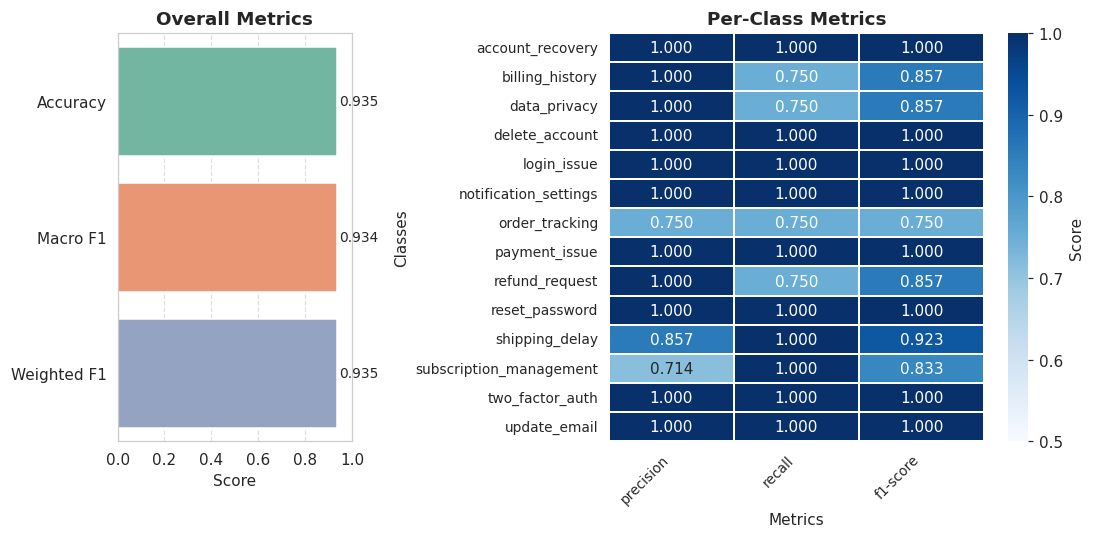

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report

# ===========================
# Predict and Compute Metrics
# ===========================
y_pred = model.predict(X_test)

acc     = accuracy_score(y_test, y_pred)
f1_mac  = f1_score(y_test, y_pred, average='macro')
f1_wt   = f1_score(y_test, y_pred, average='weighted')
report  = classification_report(y_test, y_pred, output_dict=True)

# Per-class metrics DataFrame
report_df = pd.DataFrame(report).T.drop(['accuracy'], errors='ignore')
report_df = report_df[report_df.index.isin(classes)].astype(float).round(3)

# ===========================
# Compact Figure
# ===========================
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios':[1,2]})

# --- Left: Overall Metrics ---
metrics = pd.Series([acc, f1_mac, f1_wt], index=['Accuracy', 'Macro F1', 'Weighted F1'])
sns.barplot(x=metrics.values, y=metrics.index, palette="Set2", ax=axes[0], orient='h')
axes[0].set_xlim(0, 1)
axes[0].set_title('Overall Metrics', fontsize=12, weight='bold')
axes[0].set_xlabel('Score', fontsize=10)
axes[0].set_ylabel('')
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

# Annotate bars
for i, v in enumerate(metrics.values):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=9)

# --- Right: Per-Class Heatmap ---
sns.heatmap(
    report_df[['precision','recall','f1-score']],
    annot=True, fmt=".3f",
    cmap='Blues', vmin=0.5, vmax=1.0,
    linewidths=0.3, linecolor='white',
    cbar_kws={'label':'Score'},
    ax=axes[1]
)
axes[1].set_title('Per-Class Metrics', fontsize=12, weight='bold')
axes[1].set_ylabel('Classes', fontsize=10)
axes[1].set_xlabel('Metrics', fontsize=10)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=9)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

In [21]:
# ===========================
# In detail display
# ===========================

# Overall Metrics
print("="*60)
print("         TEST SET RESULTS - Logistic Regression")
print("="*60)
print(f"Accuracy    : {acc:.4f}")
print(f"Macro F1    : {f1_mac:.4f}")
print(f"Weighted F1 : {f1_wt:.4f}")
print("="*60)
print()

# Per-Class Metrics
print("Per-Class Metrics:")
per_class_df = report_df[['precision','recall','f1-score']].copy()
print(per_class_df.to_string(float_format="{:.3f}".format))
print("="*60)

         TEST SET RESULTS - Logistic Regression
Accuracy    : 0.9355
Macro F1    : 0.9341
Weighted F1 : 0.9353

Per-Class Metrics:
                         precision  recall  f1-score
account_recovery             1.000   1.000     1.000
billing_history              1.000   0.750     0.857
data_privacy                 1.000   0.750     0.857
delete_account               1.000   1.000     1.000
login_issue                  1.000   1.000     1.000
notification_settings        1.000   1.000     1.000
order_tracking               0.750   0.750     0.750
payment_issue                1.000   1.000     1.000
refund_request               1.000   0.750     0.857
reset_password               1.000   1.000     1.000
shipping_delay               0.857   1.000     0.923
subscription_management      0.714   1.000     0.833
two_factor_auth              1.000   1.000     1.000
update_email                 1.000   1.000     1.000


## Confusion Matrix for Logistic Regression


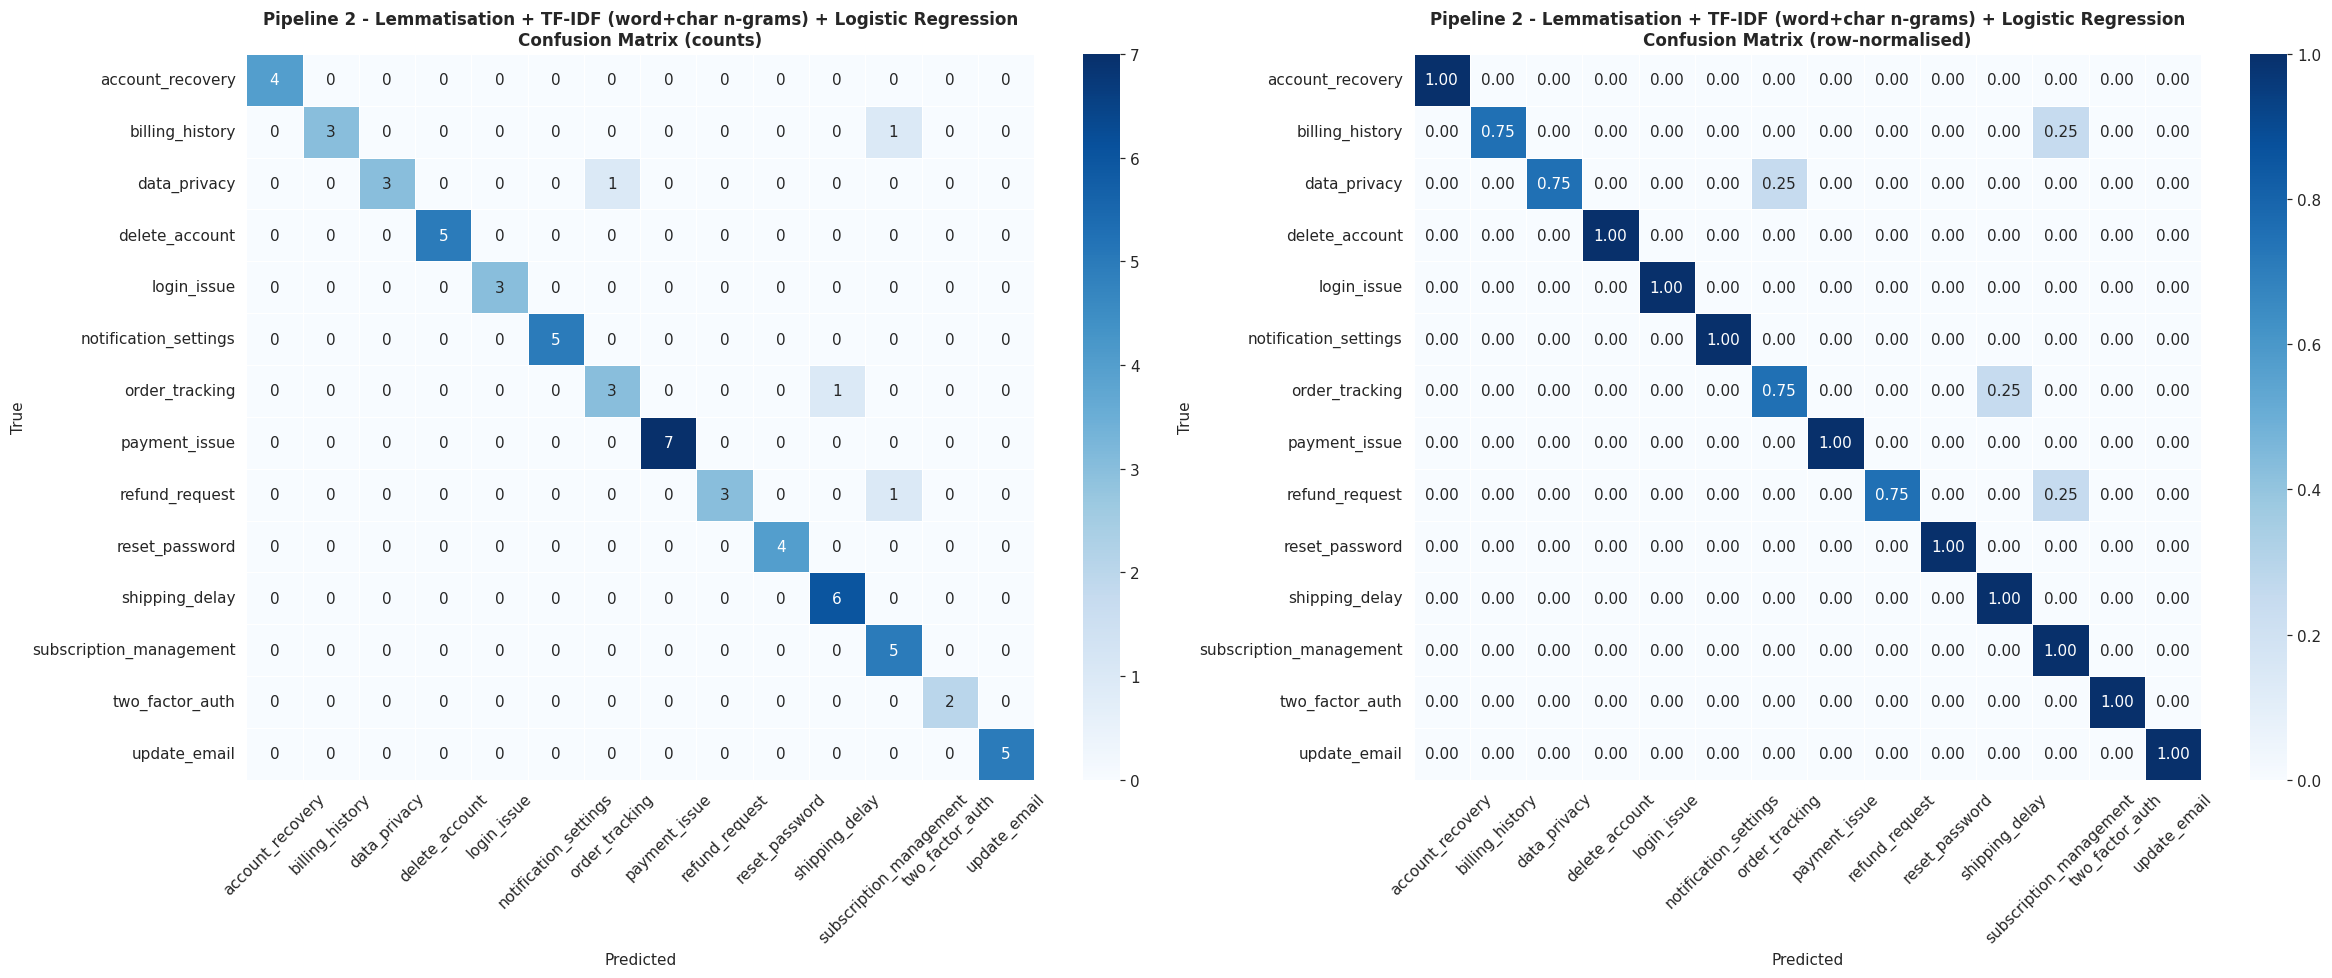

In [22]:
cm      = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, data, fmt, sfx in zip(axes,[cm,cm_norm],['d','.2f'],['(counts)','(row-normalised)']):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=classes, yticklabels=classes, linewidths=0.4, ax=ax)
    ax.set_title(f'{PIPELINE_TITLE}\nConfusion Matrix {sfx}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()


## Per-Class P/R/F1 Bar Chart Logistic Regression


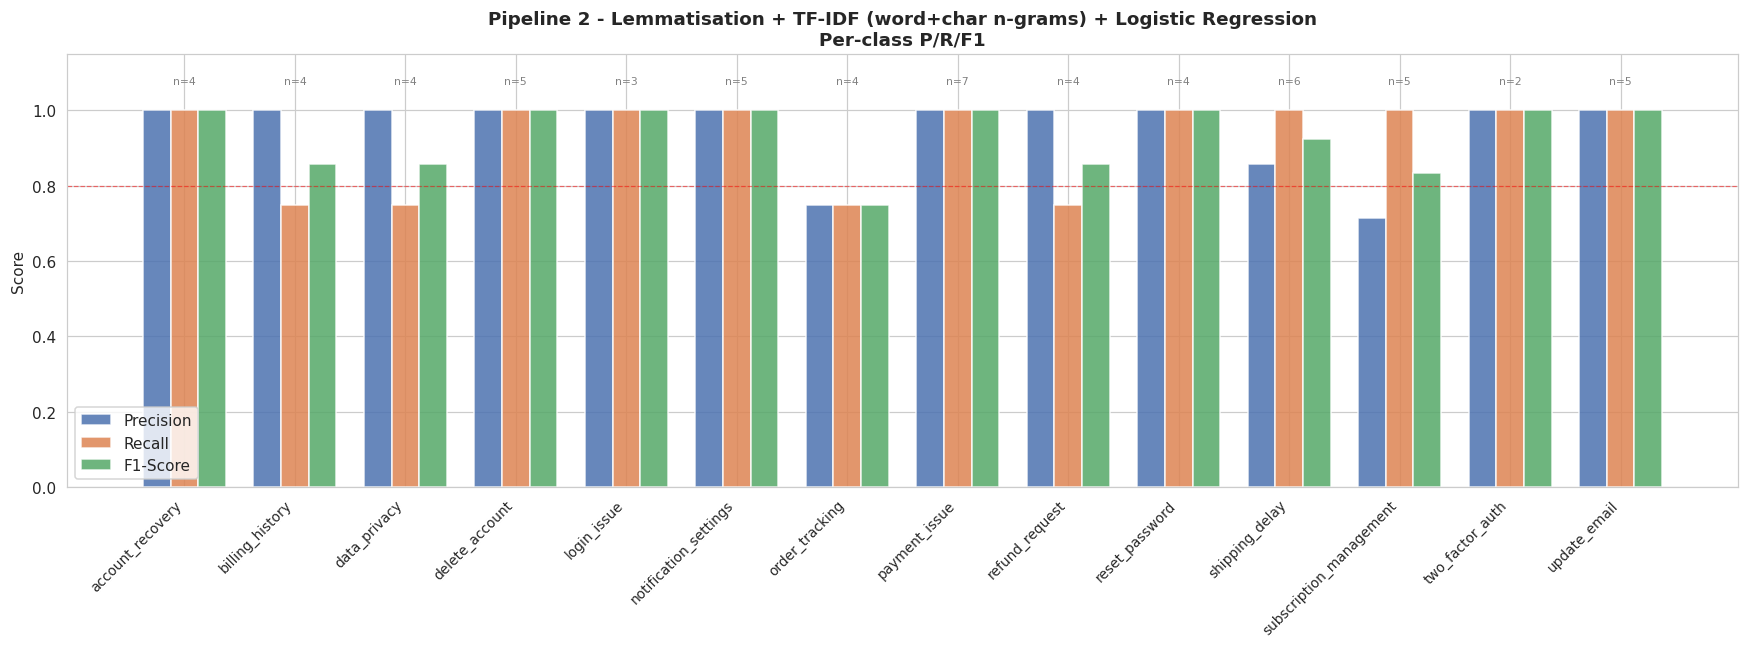

In [23]:
cls_list = [k for k in report if k not in ('accuracy','macro avg','weighted avg')]
x = np.arange(len(cls_list)); width = 0.25
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(x-width, [report[c]['precision'] for c in cls_list], width, label='Precision', color='#4C72B0', alpha=0.85)
ax.bar(x,       [report[c]['recall']    for c in cls_list], width, label='Recall',    color='#DD8452', alpha=0.85)
ax.bar(x+width, [report[c]['f1-score']  for c in cls_list], width, label='F1-Score',  color='#55A868', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(cls_list, rotation=45, ha='right', fontsize=9)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.set_title(f'{PIPELINE_TITLE}\nPer-class P/R/F1', fontweight='bold')
ax.legend(); ax.axhline(0.8, color='red', ls='--', lw=0.8, alpha=0.5)
for i, c in enumerate(cls_list):
    ax.text(x[i], 1.07, f'n={int(report[c]["support"])}', ha='center', fontsize=7, color='grey')
plt.tight_layout(); plt.show()


## ## 5 Fold Cross-Validation Logistic Regression


5-fold CV - Logistic Regression (primary)


,Fold,Accuracy,Macro F1,Weighted F1
0,Fold 1,0.854800,0.857100,0.847700
1,Fold 2,0.983900,0.985600,0.983700
2,Fold 3,0.887100,0.888500,0.885900
3,Fold 4,0.950800,0.949700,0.949900
4,Fold 5,0.901600,0.894200,0.898500
5,Mean,0.915700,0.915000,0.913100
6,Std,0.046000,0.046200,0.048100


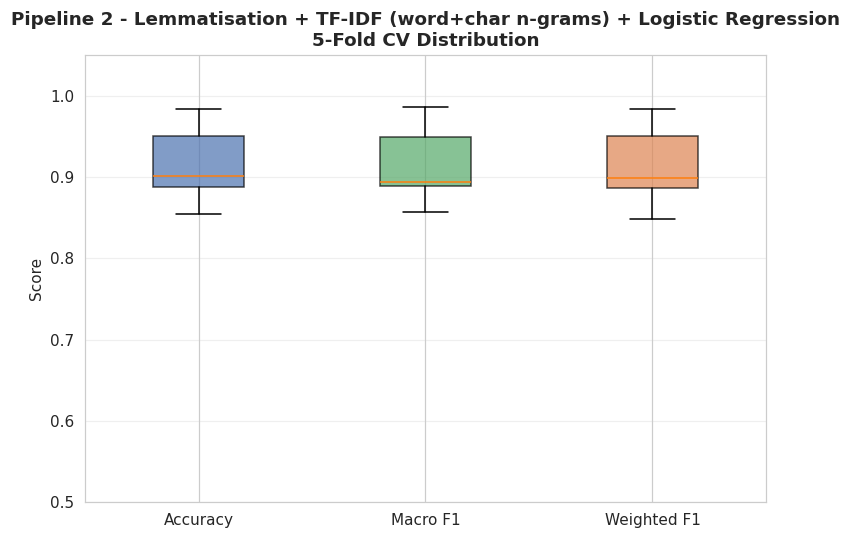

In [24]:
print('5-fold CV - Logistic Regression (primary)')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(
    build_model(), X, y, cv=cv,
    scoring={'accuracy':'accuracy','f1_macro':'f1_macro','f1_weighted':'f1_weighted'},
    return_train_score=True, n_jobs=-1,
)
cv_df = pd.DataFrame({
    'Fold':        [f'Fold {i+1}' for i in range(5)],
    'Accuracy':    cv_res['test_accuracy'].round(4),
    'Macro F1':    cv_res['test_f1_macro'].round(4),
    'Weighted F1': cv_res['test_f1_weighted'].round(4),
})
cv_df.loc['Mean'] = ['Mean', cv_res['test_accuracy'].mean().round(4),
    cv_res['test_f1_macro'].mean().round(4), cv_res['test_f1_weighted'].mean().round(4)]
cv_df.loc['Std']  = ['Std',  cv_res['test_accuracy'].std().round(4),
    cv_res['test_f1_macro'].std().round(4),  cv_res['test_f1_weighted'].std().round(4)]
display(cv_df.reset_index(drop=True).style.set_caption('5-Fold CV - Logistic Regression'))

fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot(
    [cv_res['test_accuracy'], cv_res['test_f1_macro'], cv_res['test_f1_weighted']],
    labels=['Accuracy','Macro F1','Weighted F1'], patch_artist=True, widths=0.4)
for patch, color in zip(bp['boxes'], ['#4C72B0','#55A868','#DD8452']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_ylim(0.5, 1.05); ax.set_ylabel('Score')
ax.set_title(f'{PIPELINE_TITLE}\n5-Fold CV Distribution', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y'); plt.tight_layout(); plt.show()


## - Learning Curve - Logistic Regression

Computing learning curve...


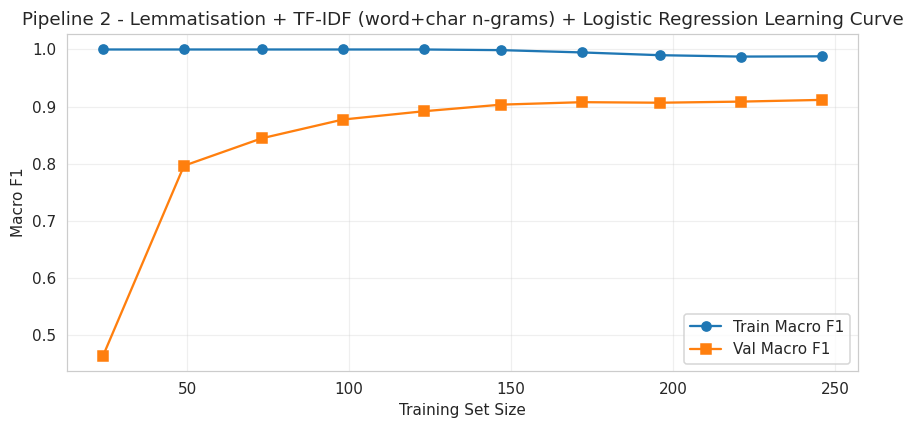

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

print('Computing learning curve...')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Compute learning curve
train_sizes = np.linspace(0.1, 1.0, 10)
tr_sz, tr_sc, vl_sc = learning_curve(
    build_model(), X, y,
    train_sizes=train_sizes,
    cv=cv, scoring='f1_macro', n_jobs=-1
)

# 2. Plot
plt.figure(figsize=(8, 4))
plt.plot(tr_sz, tr_sc.mean(1), 'o-', label='Train Macro F1')
plt.plot(tr_sz, vl_sc.mean(1), 's-', label='Val Macro F1')

# 3. Labels
plt.title(f'{PIPELINE_TITLE} Learning Curve')
plt.xlabel('Training Set Size')
plt.ylabel('Macro F1')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Prediction Confidence Histogram Logistic Regression

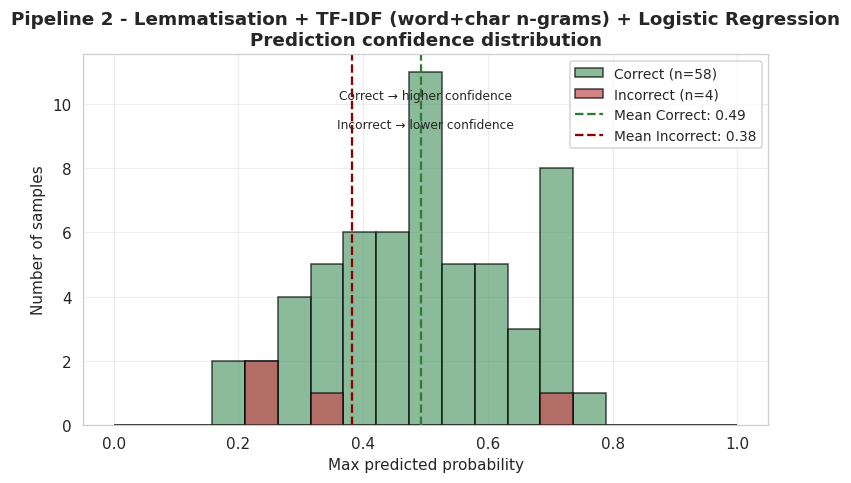

Mean confidence - Correct   : 0.492
Mean confidence - Incorrect : 0.382


In [26]:
probas   = model.predict_proba(X_test)
max_prob = probas.max(axis=1)
correct  = y_pred == y_test

# Compact figure
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(0, 1, 20)

# Histograms
ax.hist(max_prob[correct], bins=bins, alpha=0.7,
        color='#5A9E6F', edgecolor='black',
        label=f'Correct (n={correct.sum()})')

ax.hist(max_prob[~correct], bins=bins, alpha=0.7,
        color='#C44E52', edgecolor='black',
        label=f'Incorrect (n={(~correct).sum()})')

# Mean confidence lines
ax.axvline(max_prob[correct].mean(), linestyle='--', linewidth=1.5,
           color='#2E7D32',
           label=f'Mean Correct: {max_prob[correct].mean():.2f}')

ax.axvline(max_prob[~correct].mean(), linestyle='--', linewidth=1.5,
           color='#8B0000',
           label=f'Mean Incorrect: {max_prob[~correct].mean():.2f}')

# Labels and title
ax.set_xlabel('Max predicted probability', fontsize=10)
ax.set_ylabel('Number of samples', fontsize=10)
ax.set_title(f'{PIPELINE_TITLE}\nPrediction confidence distribution',
             fontsize=12, fontweight='bold')

# Simple annotations
ylim = ax.get_ylim()
ax.text(0.5, ylim[1]*0.88, 'Correct → higher confidence',
        ha='center', fontsize=8)
ax.text(0.5, ylim[1]*0.80, 'Incorrect → lower confidence',
        ha='center', fontsize=8)

# Final styling
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Mean confidence output
print(f'Mean confidence - Correct   : {max_prob[correct].mean():.3f}')
print(f'Mean confidence - Incorrect : {max_prob[~correct].mean():.3f}')

## Top TF-IDF Features per Class Logistic Regression

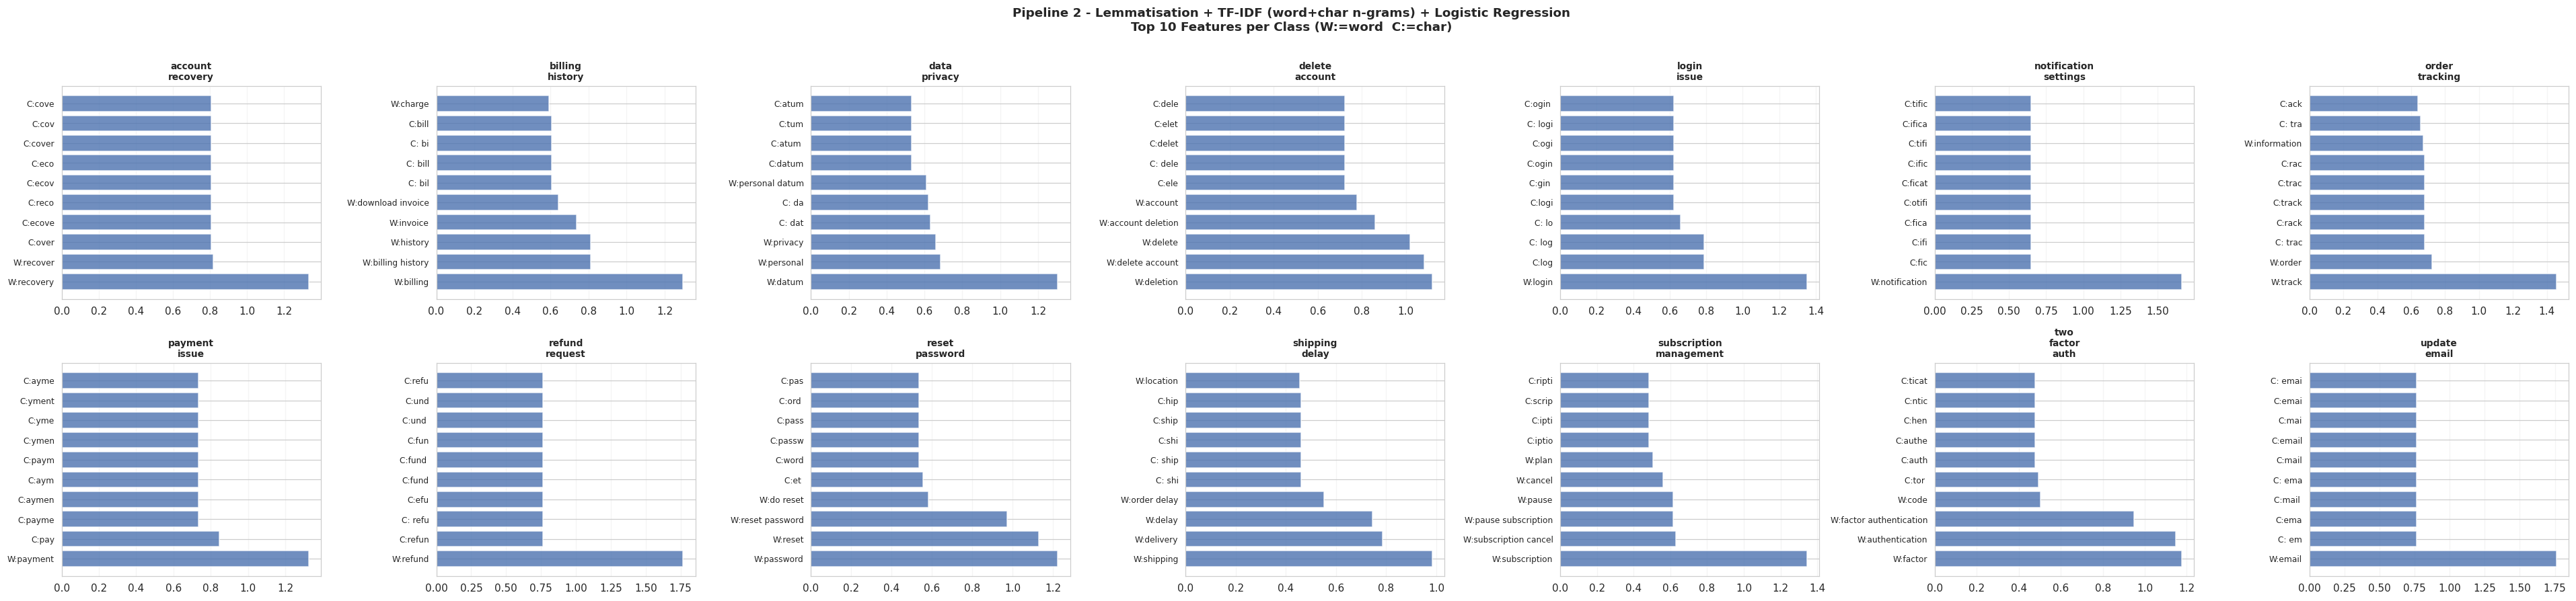

In [27]:
# Top features for primary model (Logistic Regression)
# LR coefficients accessed directly
lr_feat_union = model.named_steps['features']
lr_clf        = model.named_steps['clf']
word_names = np.array(['W:' + f for f in lr_feat_union.transformer_list[0][1].get_feature_names_out()])
char_names = np.array(['C:' + f for f in lr_feat_union.transformer_list[1][1].get_feature_names_out()])
all_names  = np.concatenate([word_names, char_names])
coef       = lr_clf.coef_

top_n = 10; ncols = 7
nrows = int(np.ceil(len(classes)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*4))
axes = axes.flatten()
for idx, cls in enumerate(classes):
    top_idx = np.argsort(coef[idx])[-top_n:][::-1]
    ax = axes[idx]
    ax.barh(range(top_n), coef[idx][top_idx][::-1], color='#4C72B0', alpha=0.8)
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(all_names[top_idx][::-1], fontsize=8)
    ax.set_title(cls.replace('_','\n'), fontsize=9, fontweight='bold')
    ax.invert_yaxis(); ax.grid(True, alpha=0.2, axis='x')
for j in range(len(classes), len(axes)): axes[j].set_visible(False)
fig.suptitle(f'{PIPELINE_TITLE}\nTop {top_n} Features per Class (W:=word  C:=char)',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


##  Summary Table

Logistic Regression Performance (Pipeline 2)

         Classifier  Test Accuracy  Test Macro F1  Test Weighted F1  CV Acc Mean  CV Macro F1 Mean  CV Macro F1 Std
Logistic Regression         0.9355         0.9341            0.9353       0.9157             0.915           0.0462


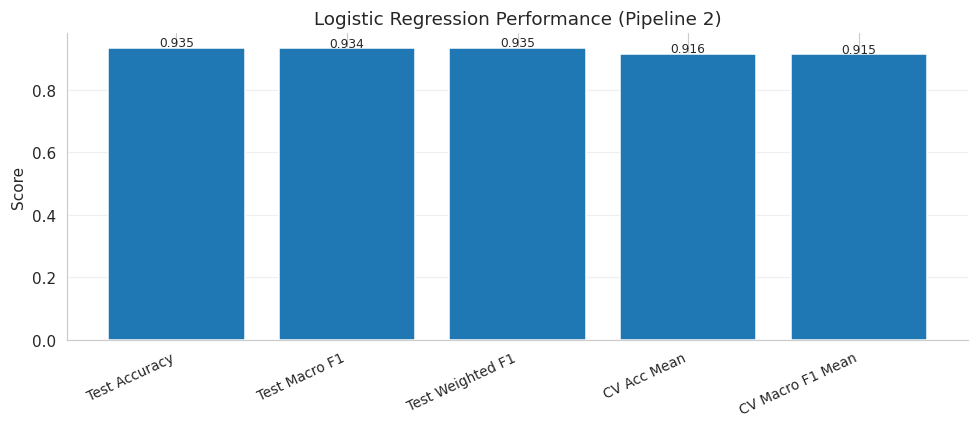


Cross-validation Macro F1 scores: [0.8571 0.9856 0.8885 0.9497 0.8942]
Mean: 0.915
Std : 0.0462

Total misclassifications: 4

Text : subscription payment history
Pred : subscription_management
True : billing_history

Text : order mark deliver do not receive
Pred : shipping_delay
True : order_tracking

Text : refund subscription cancel
Pred : subscription_management
True : refund_request

Text : access information internally
Pred : order_tracking
True : data_privacy


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Summary Table
# -------------------------
def get_metrics(name, acc, f1_mac, f1_wt, cv_res):
    return {
        'Classifier': name,
        'Test Accuracy': round(acc, 4),
        'Test Macro F1': round(f1_mac, 4),
        'Test Weighted F1': round(f1_wt, 4),
        'CV Acc Mean': round(cv_res['test_accuracy'].mean(), 4),
        'CV Macro F1 Mean': round(cv_res['test_f1_macro'].mean(), 4),
        'CV Macro F1 Std': round(cv_res['test_f1_macro'].std(), 4),
    }

lr_df = pd.DataFrame([
    get_metrics('Logistic Regression', acc, f1_mac, f1_wt, cv_res)
])

print('Logistic Regression Performance (Pipeline 2)\n')
print(lr_df.to_string(index=False))


# -------------------------
# Bar Plot (LR metrics)
# -------------------------
metrics = [
    'Test Accuracy',
    'Test Macro F1',
    'Test Weighted F1',
    'CV Acc Mean',
    'CV Macro F1 Mean'
]

lr_vals = lr_df.iloc[0][metrics].values
x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(x, lr_vals)

# Value labels
for i in range(len(metrics)):
    ax.text(x[i], lr_vals[i] + 0.005, f'{lr_vals[i]:.3f}',
            ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=9, rotation=25, ha='right')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression Performance (Pipeline 2)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


# -------------------------
# Cross-validation insight
# -------------------------
cv_scores = cv_res['test_f1_macro']

print('\nCross-validation Macro F1 scores:', np.round(cv_scores, 4))
print('Mean:', round(np.mean(cv_scores), 4))
print('Std :', round(np.std(cv_scores), 4))


# -------------------------
# Error Analysis
# -------------------------
errors = [
    (text, pred, true)
    for text, pred, true in zip(X_test, y_pred, y_test)
    if pred != true
]

print('\nTotal misclassifications:', len(errors))

for e in errors[:5]:
    print("\nText :", e[0])
    print("Pred :", e[1])
    print("True :", e[2])

## Summary of all the Graphs

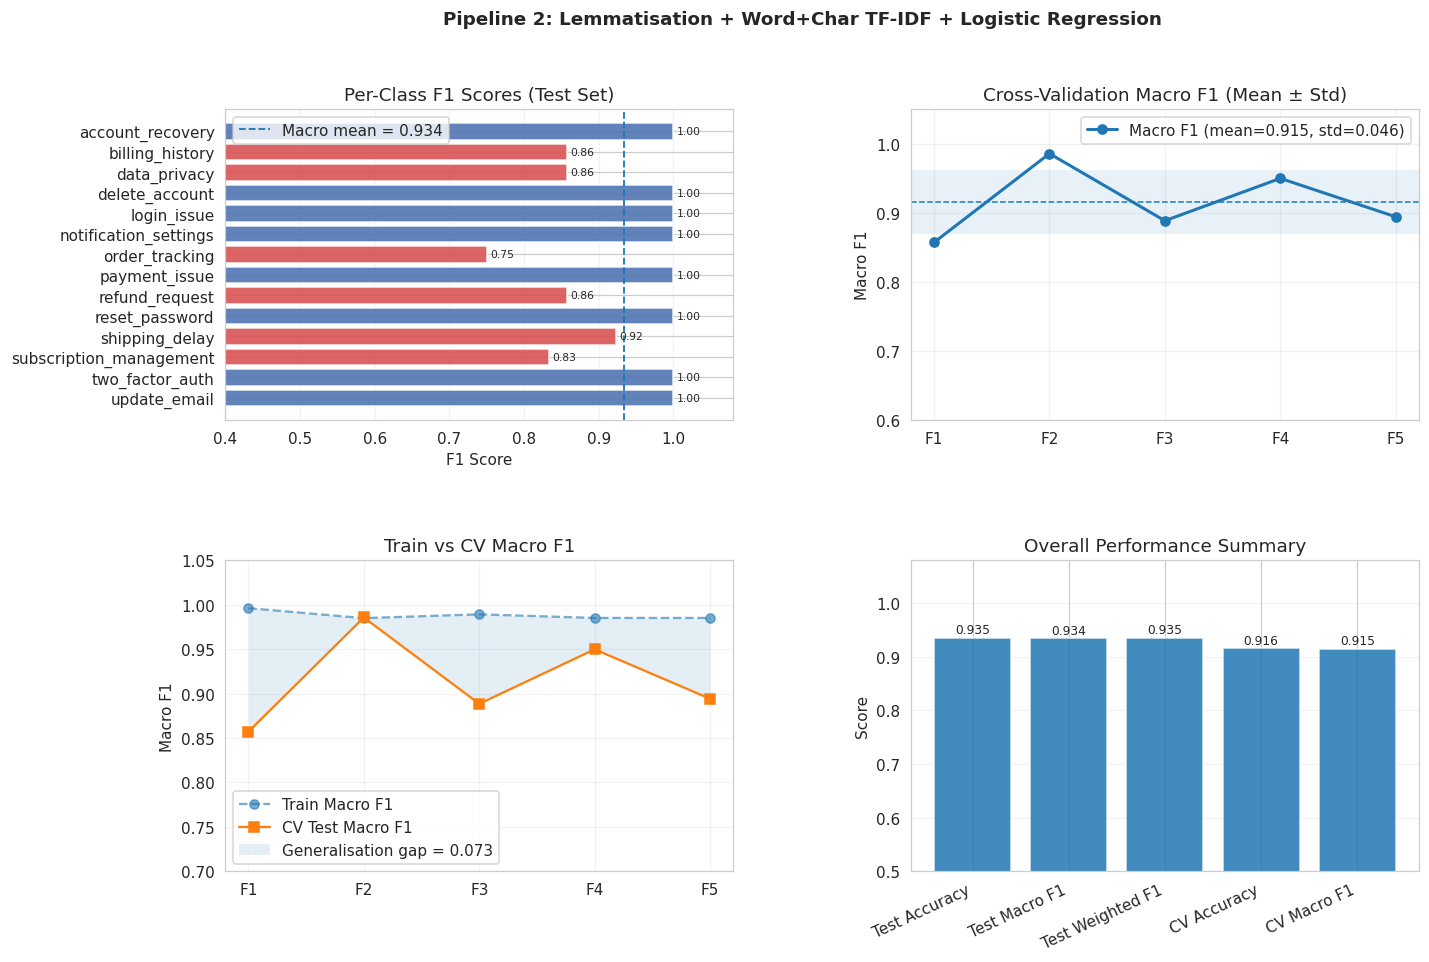

Saved: pipeline2_summary.png


In [30]:
# ===========================
# Pipeline 2 - Summary
# ===========================
# Requires: cv_res, report, acc, f1_mac, f1_wt from above

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# ---------------------------
# Panel 1: Per-class F1
# ---------------------------
ax1 = fig.add_subplot(gs[0, 0])

cls_list = [k for k in report if k not in ('accuracy','macro avg','weighted avg')]
f1_vals  = [report[c]['f1-score'] for c in cls_list]
macro_m  = np.mean(f1_vals)

colors = ['#d94f4f' if v < macro_m else '#4C72B0' for v in f1_vals]

bars = ax1.barh(cls_list, f1_vals, color=colors, alpha=0.88)

ax1.axvline(macro_m, linestyle='--', linewidth=1.2,
            label=f'Macro mean = {macro_m:.3f}')

ax1.set_xlim(0.4, 1.08)
ax1.set_xlabel('F1 Score')
ax1.set_title('Per-Class F1 Scores (Test Set)')

ax1.legend()
ax1.grid(axis='x', alpha=0.25)
ax1.invert_yaxis()

for bar, v in zip(bars, f1_vals):
    ax1.text(v + 0.005,
             bar.get_y() + bar.get_height()/2,
             f'{v:.2f}',
             va='center',
             fontsize=7)

# ---------------------------
# Panel 2: CV Stability
# ---------------------------

ax2 = fig.add_subplot(gs[0, 1])

folds = [f'F{i+1}' for i in range(5)]
x = np.arange(5)

f1m_vals = cv_res['test_f1_macro']

mean_f1 = f1m_vals.mean()
std_f1  = f1m_vals.std()

# Plot fold scores
ax2.plot(x, f1m_vals, 'o-', linewidth=2,
         label=f'Macro F1 (mean={mean_f1:.3f}, std={std_f1:.3f})')

# Proper global variability band (NOT misleading)
ax2.axhspan(mean_f1 - std_f1, mean_f1 + std_f1, alpha=0.1)

# Mean reference line
ax2.axhline(mean_f1, linestyle='--', linewidth=1)

ax2.set_xticks(x)
ax2.set_xticklabels(folds)
ax2.set_ylim(0.6, 1.05)

ax2.set_ylabel('Macro F1')
ax2.set_title('Cross-Validation Macro F1 (Mean ± Std)')

ax2.legend()
ax2.grid(alpha=0.25)
# ---------------------------
# Panel 3: Train vs CV Gap
# ---------------------------
ax3 = fig.add_subplot(gs[1, 0])

tr_f1 = cv_res['train_f1_macro']
te_f1 = cv_res['test_f1_macro']

ax3.plot(x, tr_f1, 'o--', alpha=0.6, label='Train Macro F1')
ax3.plot(x, te_f1, 's-', label='CV Test Macro F1')

gap = tr_f1.mean() - te_f1.mean()

ax3.fill_between(x, te_f1, tr_f1, alpha=0.12,
                 label=f'Generalisation gap = {gap:.3f}')

ax3.set_xticks(x)
ax3.set_xticklabels(folds)
ax3.set_ylim(0.7, 1.05)

ax3.set_ylabel('Macro F1')
ax3.set_title('Train vs CV Macro F1')

ax3.legend()
ax3.grid(alpha=0.25)

# ---------------------------
# Panel 4: Summary Metrics
# ---------------------------
ax4 = fig.add_subplot(gs[1, 1])

metric_names = [
    'Test Accuracy',
    'Test Macro F1',
    'Test Weighted F1',
    'CV Accuracy',
    'CV Macro F1'
]

metric_vals = [
    acc,
    f1_mac,
    f1_wt,
    cv_res['test_accuracy'].mean(),
    cv_res['test_f1_macro'].mean()
]

x2 = np.arange(len(metric_names))

bars4 = ax4.bar(x2, metric_vals, alpha=0.85)

ax4.set_xticks(x2)
ax4.set_xticklabels(metric_names, rotation=25, ha='right')
ax4.set_ylim(0.5, 1.08)

ax4.set_ylabel('Score')
ax4.set_title('Overall Performance Summary')

for bar, v in zip(bars4, metric_vals):
    ax4.text(bar.get_x() + bar.get_width()/2,
             v + 0.008,
             f'{v:.3f}',
             ha='center',
             fontsize=8)

ax4.grid(axis='y', alpha=0.25)

# ---------------------------
# Title
# ---------------------------
fig.suptitle(
    'Pipeline 2: Lemmatisation + Word+Char TF-IDF + Logistic Regression',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('pipeline2_summary.png', dpi=160, bbox_inches='tight')
plt.show()

print("Saved: pipeline2_summary.png")

##Final Comparison chart for both the pipelines



### Performance Comparison: Pipeline 1 vs Pipeline 2



,Classifier,Test Accuracy,Test Macro F1,Test Weighted F1,CV Acc Mean,CV Macro F1 Mean,CV Macro F1 Std
Pipeline,,,,,,,
Pipeline 1,Logistic Regression,0.9194,0.9140,0.9157,0.8929,0.8829,0.0796
Pipeline 2,Logistic Regression,0.9355,0.9341,0.9353,0.9157,0.9150,0.0462


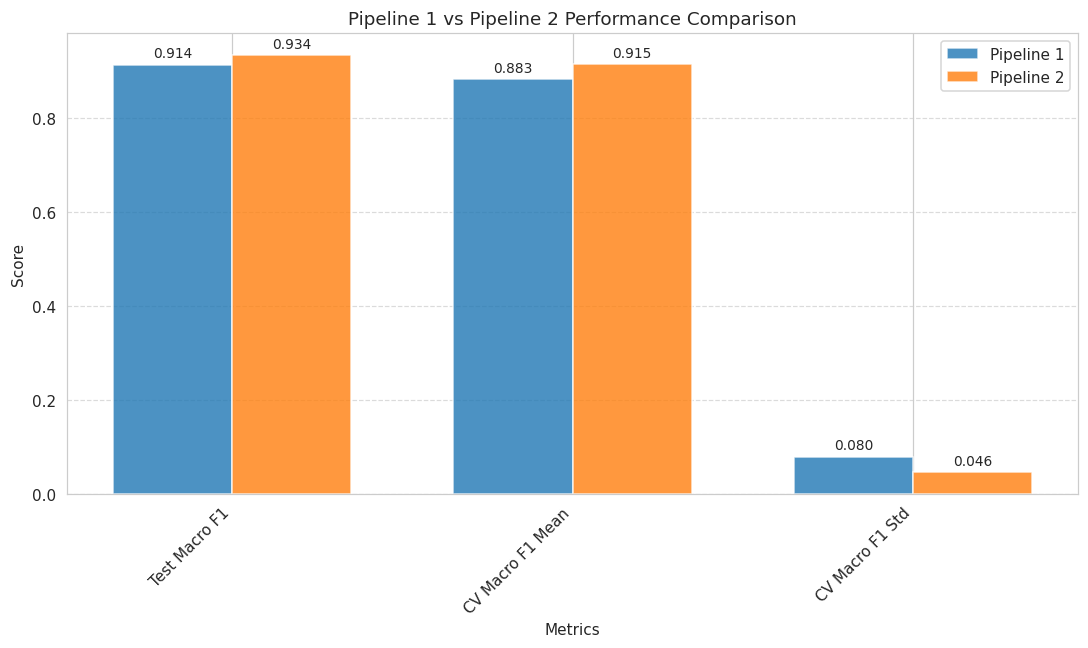

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Pipeline 1 Data taken from previous file
# For simplicity, manually parsing the string
pipeline1_data = {
    'Classifier': 'Logistic Regression',
    'Test Accuracy': 0.9194,
    'Test Macro F1': 0.914,
    'Test Weighted F1': 0.9157,
    'CV Acc Mean': 0.8929,
    'CV Macro F1 Mean': 0.8829,
    'CV Macro F1 Std': 0.0796
}

pipeline1_df = pd.DataFrame([pipeline1_data])

# Pipeline 2 Data (from previous execution, using lr_df variable)
pipeline2_df = lr_df.copy()

# Ensuring consistent column names for concatenation and plotting
pipeline1_df = pipeline1_df.rename(columns={
    'CV Acc (mean)': 'CV Acc Mean',
    'CV Macro F1 (mean)': 'CV Macro F1 Mean',
    'CV Macro F1 (std)': 'CV Macro F1 Std'
})

# Combine data for comparison
comparison_df = pd.concat([pipeline1_df, pipeline2_df.rename(index={0:'Logistic Regression'})], ignore_index=True)
comparison_df.insert(0, 'Pipeline', ['Pipeline 1', 'Pipeline 2'])

print('### Performance Comparison: Pipeline 1 vs Pipeline 2\n')
display(comparison_df.set_index('Pipeline').round(4))

# Plotting the comparison for key metrics
metrics_to_plot = ['Test Macro F1', 'CV Macro F1 Mean', 'CV Macro F1 Std']

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.35
index = np.arange(len(metrics_to_plot))

bar1 = ax.bar(index - bar_width/2, comparison_df.loc[0, metrics_to_plot], bar_width, label='Pipeline 1', alpha=0.8)
bar2 = ax.bar(index + bar_width/2, comparison_df.loc[1, metrics_to_plot], bar_width, label='Pipeline 2', alpha=0.8)

ax.set_xlabel('Metrics')
ax.set_ylabel('Score')
ax.set_title('Pipeline 1 vs Pipeline 2 Performance Comparison')
ax.set_xticks(index)
ax.set_xticklabels(metrics_to_plot, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(bar1)
autolabel(bar2)

plt.tight_layout()
plt.show()